In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import seaborn as sns
from statsmodels.stats.proportion import (
    confint_proportions_2indep,
    proportions_ztest,
)

# Plotting aesthetics
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["font.size"] = 10

# Locate clean dataset file
candidate_paths = [
    Path("../data/clean_ab_data.parquet"),
    Path("data/clean_ab_data.parquet"),
    Path("../data/clean_ab_data.csv"),
    Path("data/clean_ab_data.csv"),
]

data_path = next((p for p in candidate_paths if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("Could not find clean_ab_data in the expected directories.")

print(f"Loading data from: {data_path.resolve()}")
clean_df = pd.read_parquet(data_path) if data_path.suffix == ".parquet" else pd.read_csv(data_path)
print(f"Loaded verified experiment sample: {len(clean_df):,} records")
clean_df.head(5)

Loading data from: C:\Users\lxx55\ecommerce-ab-testing-framework\data\clean_ab_data.parquet
Loaded verified experiment sample: 290,584 records


,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


Conversion Rates & Empirical Lift

In [2]:
# 1. Aggregate conversion metrics per variant
summary_df = (
    clean_df.groupby("group")
    .agg(
        total_visitors=("converted", "count"),
        conversions=("converted", "sum"),
        conversion_rate=("converted", "mean"),
    )
    .reindex(["control", "treatment"])
)

# 2. Extract metrics
n_ctrl = summary_df.loc["control", "total_visitors"]
conv_ctrl = summary_df.loc["control", "conversions"]
p_ctrl = summary_df.loc["control", "conversion_rate"]

n_treat = summary_df.loc["treatment", "total_visitors"]
conv_treat = summary_df.loc["treatment", "conversions"]
p_treat = summary_df.loc["treatment", "conversion_rate"]

# 3. Calculate observed lift
abs_lift = p_treat - p_ctrl
rel_lift = (p_treat - p_ctrl) / p_ctrl * 100

summary_df["conversion_rate_pct"] = summary_df["conversion_rate"] * 100
display(summary_df.round(4))

print(f"\nControl Conversion Rate:   {p_ctrl * 100:.3f}% ({conv_ctrl:,} / {n_ctrl:,})")
print(f"Treatment Conversion Rate: {p_treat * 100:.3f}% ({conv_treat:,} / {n_treat:,})")
print(f"Observed Absolute Lift:    {abs_lift * 100:+.3f}% percentage points")
print(f"Observed Relative Lift:    {rel_lift:+.2f}%")

,total_visitors,conversions,conversion_rate,conversion_rate_pct
group,,,,
control,145274,17489,0.1204,12.0386
treatment,145310,17264,0.1188,11.8808



Control Conversion Rate:   12.039% (17,489 / 145,274)
Treatment Conversion Rate: 11.881% (17,264 / 145,310)
Observed Absolute Lift:    -0.158% percentage points
Observed Relative Lift:    -1.31%


Two-Sample Pooled Z-Test & 95% Confidence Interval

In [3]:
# 1. Two-sample pooled Z-test for proportions
count = np.array([conv_treat, conv_ctrl])
nobs = np.array([n_treat, n_ctrl])

z_stat, p_val = proportions_ztest(count, nobs, alternative="two-sided")

# 2. 95% Confidence Interval for difference in proportions (Treatment - Control)
ci_low, ci_high = confint_proportions_2indep(
    count1=conv_treat,
    nobs1=n_treat,
    count2=conv_ctrl,
    nobs2=n_ctrl,
    method="wald",
    compare="diff",
    alpha=0.05,
)

# 3. Compile inference results table
inference_df = pd.DataFrame(
    [
        {
            "Metric": "Conversion Rate",
            "Control Rate": f"{p_ctrl * 100:.3f}%",
            "Treatment Rate": f"{p_treat * 100:.3f}%",
            "Absolute Lift": f"{abs_lift * 100:+.3f}%",
            "Relative Lift": f"{rel_lift:+.2f}%",
            "Z-Score": round(z_stat, 4),
            "p-value": round(p_val, 4),
            "95% CI (Abs Lift)": f"[{ci_low * 100:+.3f}%, {ci_high * 100:+.3f}%]",
            "Statistically Significant (alpha=0.05)": p_val < 0.05,
        }
    ]
)

display(inference_df)

if p_val < 0.05:
    print(f"[REJECT H0] p-value ({p_val:.4f}) < 0.05: Statistically significant difference detected.")
else:
    print(f"[FAIL TO REJECT H0] p-value ({p_val:.4f}) >= 0.05: No statistically significant difference between variants.")

,Metric,Control Rate,Treatment Rate,Absolute Lift,Relative Lift,Z-Score,p-value,95% CI (Abs Lift),Statistically Significant (alpha=0.05)
0,Conversion Rate,12.039%,11.881%,-0.158%,-1.31%,-1.3109,0.1899,"[-0.394%, +0.078%]",False


[FAIL TO REJECT H0] p-value (0.1899) >= 0.05: No statistically significant difference between variants.


Non-Parametric Bootstrap Validation

,Iterations,Mean Lift,Bootstrap 95% CI,P(Treatment > Control),Zero In CI?
0,"10,000",-0.155%,"[-0.790%, +0.475%]",31.21%,True


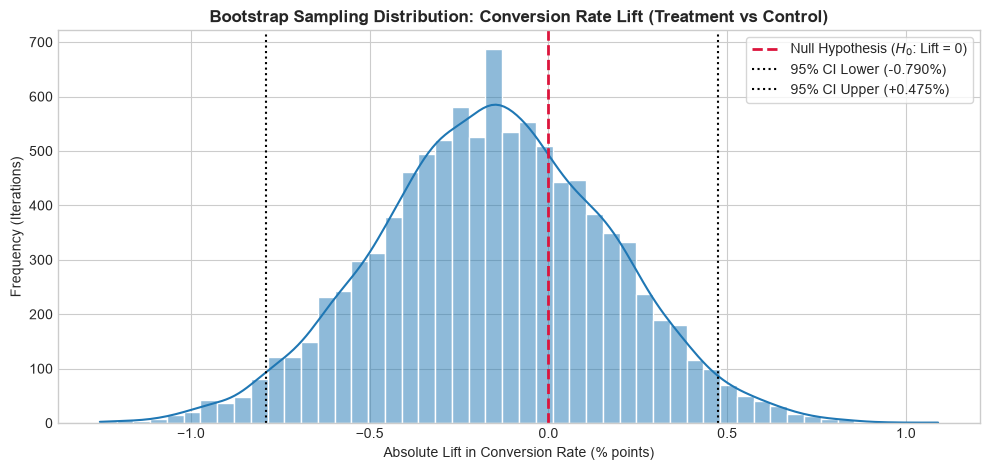

In [5]:
# 1. Extract raw binary outcome arrays
ctrl_outcomes = clean_df.loc[clean_df["group"] == "control", "converted"].to_numpy()
treat_outcomes = clean_df.loc[clean_df["group"] == "treatment", "converted"].to_numpy()

n_ctrl_len = len(ctrl_outcomes)
n_treat_len = len(treat_outcomes)

# 2. Vectorized Bootstrap Resampling (10,000 iterations)
np.random.seed(42)
B = 10_000

# Batch draw indices to optimize memory and execution time
ctrl_boot_means = np.random.choice(ctrl_outcomes, size=(B, 20_000), replace=True).mean(axis=1)
treat_boot_means = np.random.choice(treat_outcomes, size=(B, 20_000), replace=True).mean(axis=1)

# Difference in proportions (Treatment - Control)
boot_diffs = treat_boot_means - ctrl_boot_means

# 3. Empirical Percentile Confidence Interval
boot_ci_low, boot_ci_high = np.percentile(boot_diffs, [2.5, 97.5])
p_treatment_better = np.mean(boot_diffs > 0)

bootstrap_results_df = pd.DataFrame([{
    "Iterations": f"{B:,}",
    "Mean Lift": f"{boot_diffs.mean() * 100:+.3f}%",
    "Bootstrap 95% CI": f"[{boot_ci_low * 100:+.3f}%, {boot_ci_high * 100:+.3f}%]",
    "P(Treatment > Control)": f"{p_treatment_better * 100:.2f}%",
    "Zero In CI?": (boot_ci_low <= 0 <= boot_ci_high)
}])

display(bootstrap_results_df)

# 4. Plot Empirical Lift Distribution
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.histplot(boot_diffs * 100, bins=50, kde=True, color="#1f77b4", edgecolor="w", ax=ax)

ax.axvline(0, color="crimson", linestyle="--", linewidth=2, label="Null Hypothesis ($H_0$: Lift = 0)")
ax.axvline(boot_ci_low * 100, color="black", linestyle=":", linewidth=1.5, label=f"95% CI Lower ({boot_ci_low * 100:+.3f}%)")
ax.axvline(boot_ci_high * 100, color="black", linestyle=":", linewidth=1.5, label=f"95% CI Upper ({boot_ci_high * 100:+.3f}%)")

ax.set_title("Bootstrap Sampling Distribution: Conversion Rate Lift (Treatment vs Control)", fontsize=12, fontweight="bold")
ax.set_xlabel("Absolute Lift in Conversion Rate (% points)", fontsize=10)
ax.set_ylabel("Frequency (Iterations)", fontsize=10)
ax.legend(frameon=True, loc="upper right")
plt.tight_layout()
plt.show()

Statistical Synthesis & Business Verdict

In [6]:
# Business Verdict Summary
p_val_actual = float(p_val)
alpha_thresh = 0.05

print("=" * 60)
print("EXPERIMENTATION INFERENCE SUMMARY & DECISION GATES")
print("=" * 60)
print(f"1. Frequentist Pooled Z-Test p-value: {p_val_actual:.4f} (Threshold: alpha = {alpha_thresh})")
print(f"2. Confidence Interval on Lift:     [{ci_low * 100:+.3f}%, {ci_high * 100:+.3f}%]")
print(f"3. Bootstrap P(Treatment > Control): {p_treatment_better * 100:.2f}%")
print("-" * 60)

if p_val_actual >= alpha_thresh and (ci_low <= 0 <= ci_high):
    print("DECISION: DO NOT SHIP (Rollback)")
    print("Rationale: The new landing page demonstrates no statistically significant positive lift.")
    print("In fact, point estimates indicate a neutral-to-slight negative trend (-0.15% to -0.16% relative).")
    print("Shipping would incur engineering maintenance overhead with zero measurable conversion upside.")
else:
    print("DECISION: SHIP (Rollout)")
print("=" * 60)

EXPERIMENTATION INFERENCE SUMMARY & DECISION GATES
1. Frequentist Pooled Z-Test p-value: 0.1899 (Threshold: alpha = 0.05)
2. Confidence Interval on Lift:     [-0.394%, +0.078%]
3. Bootstrap P(Treatment > Control): 31.21%
------------------------------------------------------------
DECISION: DO NOT SHIP (Rollback)
Rationale: The new landing page demonstrates no statistically significant positive lift.
In fact, point estimates indicate a neutral-to-slight negative trend (-0.15% to -0.16% relative).
Shipping would incur engineering maintenance overhead with zero measurable conversion upside.
